## 회귀 모델 (알고리즘)
- 회귀: 연속적인 수치(숫자)를 예측하는 모델
- 분류 vs 회귀
    - 분류: 범주(ex. up/down)를 예측하며, 예측이 맞았는지 틀렸는지가 명확하다. (혼동행렬, 정확도 등으로 판단)
    - 회귀: 연속적인 수치(ex. 수익률)를 예측하며, 정확히 맞았다는 개념이 없어 오차의 크기를 측정한다. (MAE, RMSE, R² 등으로 판단)
> **회귀에서는 오차의 크기(즉, 실제와 얼마나 가까운지)가 가장 중요**\
> 참고: **로지스틱 회귀**는 이름만 회귀이고, 선형 계산 후 확률을 통해 범주를 판단하는 **분류 모델**이다.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from _ml import build_dataset, time_split, FEATURES, SEED
from _style import setup

setup()
pd.set_option("display.width", 130)

df = build_dataset()
train, test, cutoff = time_split(df)

# 데이터 샘플 추출
tr = train.sample(15_000, random_state=SEED)
te = test.sample(4_000, random_state=SEED)

# 피처 분리
X_train, X_test = tr[FEATURES], te[FEATURES]

# 정답(y)을 두 종류(분류(target_up)와 회귀(target_ret))로 준비
# 분류용 정답: 상승(1) / 하락 및 유지(0)
y_train_cls, y_test_cls = tr["target_up"], te["target_up"]
# 회귀용 정답: 수익률(수치)
y_train_reg, y_test_reg = tr["target_ret"], te["target_ret"]

print(f"* 학습: {len(tr):,}행"
      f" ({tr['date'].min().date()} ~ {tr['date'].max().date()})")
print(f"* 테스트: {len(te):,}행"
      f" ({te['date'].min().date()} ~ {te['date'].max().date()})")
print(f"* 피처 {len(FEATURES)}개")
print()
print(f"- 분류용 정답(target_up): {y_train_cls.unique()} (범주)")
print(f"- 회귀용 정답(target_ret):"
      f" {y_train_reg.min():.4f} ~ {y_train_reg.max():.4f} (수치)")

* 학습: 15,000행 (2023-10-24 ~ 2026-01-16)
* 테스트: 4,000행 (2026-01-19 ~ 2026-09-07)
* 피처 7개

- 분류용 정답(target_up): [0 1] (범주)
- 회귀용 정답(target_ret): -0.2260 ~ 0.2313 (수치)


- 분류: y = target_up (0/1) --> RandomForestClassifier
- 회귀: y = target_ret (수익률) --> RandomForestRegressor

**동일한 이름의 알고리즘이지만, 평가 방법은 완전히 다르다.**
- RandomForestClassifier: accuracy_score(정확도), f1_score(f1 점수)
- RandomForestRegressor: mean_absolute_error, mean_squared_error, r2_score

In [3]:
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor

                            # 분류 평가지표
from sklearn.metrics import (accuracy_score, f1_score,
                            # 회귀 평가지표
                             mean_absolute_error, mean_squared_error, r2_score)

# n_estimators는 기본값이 100이라 생략 가능
clf = RandomForestClassifier(n_estimators=100, max_depth=6,
                             random_state=SEED, n_jobs=-1)
reg = RandomForestRegressor(n_estimators=100, max_depth=6,
                            random_state=SEED, n_jobs=-1)

# 학습: fit(X_train, y_train)
clf.fit(X_train, y_train_cls)   # 분류 모델 학습
reg.fit(X_train, y_train_reg)   # 회귀 모델 학습

# 예측: predict(X_test)
pred_cls = clf.predict(X_test)    # 분류 모델 예측
pred_reg = reg.predict(X_test)    # 회귀 모델 예측

print(f"{'':<14}{'분류':<32}{'회귀'}")
print("-" * 70)
print(f"{'정답예시':<13}{y_test_cls.iloc[0]:<32}{y_test_reg.iloc[0]:.4f}")
print(f"{'예측예시':<13}{pred_cls[0]:<32}{pred_reg[0]:.4f}")
print()
print(f"분류 평가: 정확도 {accuracy_score(y_test_cls, pred_cls):.4f}")
print(f"           f1     {f1_score(y_test_cls, pred_cls):.4f}")
print(f"회귀 평가: RMSE {np.sqrt(mean_squared_error(y_test_reg, pred_reg)):.6f}")
print(f"           R²   {r2_score(y_test_reg, pred_reg):.4f}")

              분류                              회귀
----------------------------------------------------------------------
정답예시         0                               -0.0068
예측예시         1                               -0.0000

분류 평가: 정확도 0.4933
           f1     0.4269
회귀 평가: RMSE 0.027389
           R²   -0.0068


In [4]:
# 0을 기준으로 회귀 예측을 나누어서 분류

# df["target_ret"] = df.groupby("code")["close"].pct_change()
# 즉, target_ret의 값이 0보다 크면 up이 됨.
reg_to_cls = (pred_reg > 0).astype(int)

print(f"회귀 모델의 예측값에서 0을 기준으로 범주화 했을 때 정확도\n"
      f": {accuracy_score(y_test_cls, reg_to_cls):.4f}")
print(f"분류 모델로 학습한 정확도\n"
      f": {accuracy_score(y_test_cls, pred_cls):.4f}")

회귀 모델의 예측값에서 0을 기준으로 범주화 했을 때 정확도
: 0.4793
분류 모델로 학습한 정확도
: 0.4933


---
## LinearRegression (선형 회귀)
가장 단순한 선형 회귀 모델. 직선으로 관계를 표현.
`예측값 = w₁x + w₂x + ... + b`
(현재 데이터에서는 `예측값 = w₁ret_1d + w₂ret_5d + ... + b`)

- 학습: **MSE가 가장 작아지는** 가중치(w)와 절편(b)을 찾는 것.
    - w (가중치, 계수, 기울기): 다른 피처가 그대로일 때, 해당 피처가 1 증가할 때 예측값의 변화량
    - b (절편): 편향


In [5]:
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
# 각 피처의 평균을 0, 표준편차를 1로 맞춰주는 스케일러
from sklearn.preprocessing import StandardScaler

def make(model):
    return Pipeline([
        ("sc", StandardScaler()),
        ("m", model)
        ])

lin = make(LinearRegression())

lin.fit(X_train, y_train_reg)

# 절편(b), 계수(w) 확인
# lin.named_steps["m"]: 모델 객체를 추출
# 모델.coef_: 가중치(계수) 배열
coef = pd.Series(lin.named_steps["m"].coef_, index=FEATURES).sort_values()

# 모델.intercept_: 절편(편향) 값 확인
intercept = lin.named_steps["m"].intercept_

print(f"* 절편 b = {intercept:.6f}\n")
print("* 가중치 w")
print(coef.round(6).to_string())

* 절편 b = -0.000063

* 가중치 w
vol20          -0.000567
ma20_ratio     -0.000507
volume_ratio   -0.000161
range_pct       0.000055
ma5_ratio       0.000117
ret_5d          0.000544
ret_1d          0.000756


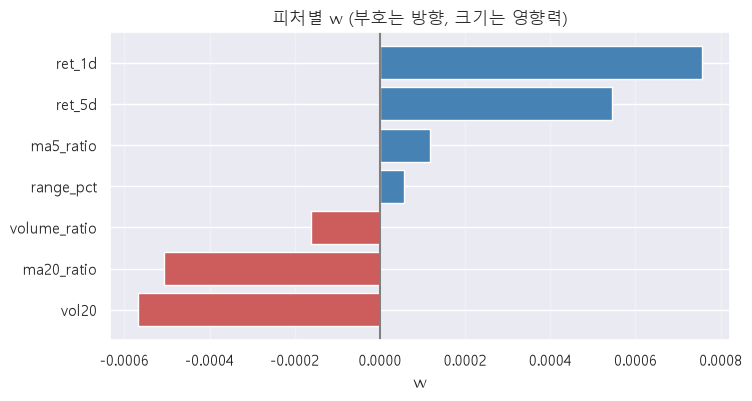

In [6]:
fig, ax = plt.subplots(figsize=(8, 4))

# 0 이상은 파랑, 0 미만은 빨강으로 표시
colors = ["indianred" if v < 0 else "steelblue" for v in coef.values]

ax.barh(coef.index, coef.values, color=colors)
ax.axvline(0, color="gray")
ax.set_xlabel("w")
ax.set_title("피처별 w (부호는 방향, 크기는 영향력)")
ax.grid(alpha=0.3, axis="x")

plt.show()

#### 계수(가중치)는 해석을 도와주는 지표
계수의 부호는 방향(+는 증가, -는 감소)을, 절댓값은 영향력의 크기를 알려준다.\
다만, 피처의 스케일(단위)이 다르면 계수 크기를 직접 비교할 수 없으므로 **스케일링을 먼저** 진행해야 한다.

또한 피처끼리 서로 비슷하면(다중공산성) 계수가 불안정해져서 해석이 틀어질 수 있다.\
(우리 데이터의 계수는 모두 0에 가까운 아주 작은 값이므로, 선형 관계가 거의 없다고 볼 수 있다.)

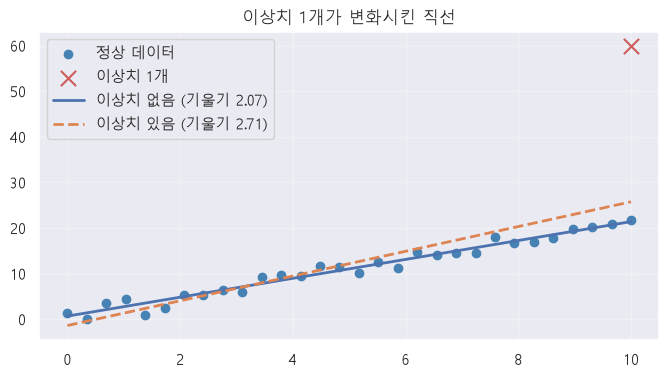

In [8]:
# 이상치를 하나 넣어서 직선의 변화를 확인해보기

# 난수 생성기
rng = np.random.default_rng(SEED)

# 폐구간 [0 10]의 30등분점 목록
x_demo = np.linspace(0, 10, 30)
# y = 2x + 1에 노이즈 추가 (평균 0, 표준편차 1.5인 오차 30개)
y_demo = 2 * x_demo + 1 + rng.normal(0, 1.5, 30)

# 이상치 1개 추가 (x = 10이면 y ≒ 21 근처여야 하는데, y = 60)
x_bad = np.append(x_demo, 10)
y_bad = np.append(y_demo, 60)

fig, ax = plt.subplots(figsize=(8, 4))

ax.scatter(x_demo, y_demo, label="정상 데이터", color="steelblue")
ax.scatter([10], [60], s=120, label="이상치 1개", color="indianred", 
           marker="x", zorder=5)

datas = [
    # (x, y, display, name)
    (x_demo, y_demo, "-", "이상치 없음"),
    (x_bad, y_bad, "--", "이상치 있음")
]

for xs, ys, d, name in datas:
    m = LinearRegression().fit(xs.reshape(-1, 1), ys)

    xx = np.linspace(0, 10, 10)
    ax.plot(xx, m.predict(xx.reshape(-1, 1)), d,
            lw=2, label=f"{name} (기울기 {m.coef_[0]:.2f})")

ax.legend()
ax.grid(alpha=0.3)
ax.set_title("이상치 1개가 변화시킨 직선")

plt.show()

#### 이상치 하나가 직선을 끌고가는 것을 확인할 수 있다.
선형 회귀는 오차의 제곱을 최소화한다. 크게 빗나간 데이터(이상치)가 제곱되면서 영향력이 매우 커지게 된다.